# Chapter 59: Exchange Rates, Capital Flows, Crises, and Open-Economy Policy

This notebook reruns four worked examples from the chapter: exchange-rate overshooting after a monetary expansion, covered interest parity, the Balassa-Samuelson effect and the J-curve. Every example is hypothetical, as in the book; a few extra input values are added for comparison.

## Setup

The functions below are the calculations behind every number in this notebook. Run this cell first.

In [1]:
import math
from types import SimpleNamespace

import numpy as np
import matplotlib
import matplotlib.pyplot as plt



PALETTE = {
    "ink": "#172a3b",
    "teal": "#136f75",
    "gold": "#8f5d0f",
    "navy": "#334c72",
    "terracotta": "#a24a33",
    "olive": "#5d6a37",
    "grey": "#6b757b",
    "light": "#c9d3d6",
}


CYCLE = ["teal", "navy", "gold", "terracotta", "olive", "grey"]


LABEL_SIZE = 10.5


HOUSE_RC = {
    "font.size": 11.5,
    "axes.titlesize": 12,
    "axes.labelsize": 11.5,
    "xtick.labelsize": 10.5,
    "ytick.labelsize": 10.5,
    "legend.fontsize": 10.5,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": "#6b757b",
    "axes.labelcolor": "#172a3b",
    "xtick.color": "#172a3b",
    "ytick.color": "#172a3b",
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "svg.fonttype": "path",
}


def color(name_or_index):
    """Palette colour by name ('teal') or by position in the series cycle (0, 1, ...)."""
    if isinstance(name_or_index, int):
        return PALETTE[CYCLE[name_or_index % len(CYCLE)]]
    return PALETTE.get(name_or_index, name_or_index)


def tex_safe(text):
    """Escape dollar signs so Matplotlib does not read '$...$' as mathematics."""
    return str(text).replace("\\$", "$").replace("$", r"\$")


def new_figure(ncols=1, width=None, height=4.3):
    """Notebook twin of readerkit.new_figure: one panel 6.6 x 4.3 in, two panels 10.4 x 4.3 in."""
    import matplotlib.pyplot as plt

    if width is None:
        width = 6.6 if ncols == 1 else 10.4
    fig, axes = plt.subplots(1, ncols, figsize=(width, height), layout="constrained")
    for ax in (axes if ncols > 1 else [axes]):
        ax.grid(alpha=0.18)
    return fig, axes


def label(ax, x, y, text, col="ink", dx=6, dy=6, ha="left", va="bottom", box=True, size=LABEL_SIZE):
    """Direct label at data point (x, y) offset by (dx, dy) points, with a white box by default."""
    kw = {}
    if box:
        kw["bbox"] = {"boxstyle": "round,pad=0.18", "fc": "white", "ec": "none", "alpha": 0.9}
    return ax.annotate(tex_safe(text), (x, y), xytext=(dx, dy), textcoords="offset points", ha=ha, va=va,
                       color=color(col), fontsize=size, **kw)


def mark(ax, x, y, text=None, col="ink", size=42, dx=6, dy=6, ha="left", va="bottom", zorder=5):
    """Filled point with an optional direct label."""
    ax.scatter([x], [y], s=size, color=color(col), zorder=zorder)
    if text:
        label(ax, x, y, text, col=col, dx=dx, dy=dy, ha=ha, va=va)


def hline(ax, y, text=None, col="grey", style="dashed", x_frac=0.02, va="bottom", lw=1.4):
    """Horizontal reference line with an optional label at the left edge."""
    ax.axhline(y, color=color(col), linestyle=style, linewidth=lw)
    if text:
        ax.annotate(tex_safe(text), (x_frac, y), xycoords=("axes fraction", "data"), xytext=(0, 4 if va == "bottom" else -4),
                    textcoords="offset points", ha="left", va=va, color=color(col), fontsize=LABEL_SIZE,
                    bbox={"boxstyle": "round,pad=0.18", "fc": "white", "ec": "none", "alpha": 0.9})


def bar_compare(ax, names, values, colors=None, value_labels=None, ylabel="Value", xlabel="Item", fmt=None,
                zero_line=True):
    """Labelled vertical bars, one per name; each bar carries its value label.

    ``value_labels`` gives the text over each bar (else ``fmt(v)`` or '{:,.2f}').
    Negative bars are allowed; labels go below them.
    """
    values = [float(v) for v in values]
    colors = colors or [color(i) for i in range(len(values))]
    xs = np.arange(len(values))
    ax.bar(xs, values, color=[color(c) for c in colors], width=0.6)
    ax.set_xticks(xs, names)
    lo, hi = min(0.0, min(values)), max(0.0, max(values))
    span = (hi - lo) or 1.0
    ax.set_ylim(lo - (0.14 * span if lo < 0 else 0), hi + 0.16 * span)
    for x, v, i in zip(xs, values, range(len(values))):
        text = value_labels[i] if value_labels else (fmt(v) if fmt else f"{v:,.2f}")
        ax.annotate(text, (x, v), xytext=(0, 4 if v >= 0 else -4), textcoords="offset points", ha="center",
                    va="bottom" if v >= 0 else "top", fontsize=LABEL_SIZE, color=PALETTE["ink"])
    if zero_line and lo < 0:
        ax.axhline(0, color=PALETTE["grey"], linewidth=1)
    ax.set_ylabel(ylabel)
    ax.set_xlabel(xlabel)
    return ax


def num(value, digits=2, comma=True):
    """Fixed-decimal string with optional thousands separators: num(1444.444) -> '1,444.44'.

    Negative zero prints as '0'. Raises ValueError on NaN or infinity, because an
    undefined value must be named in words (see ``undefined``).
    """
    value = float(value)
    if not math.isfinite(value):
        raise ValueError("non-finite value; name it with undefined(reason)")
    text = f"{value:,.{digits}f}" if comma else f"{value:.{digits}f}"
    if text.startswith("-") and float(text.replace(",", "")) == 0:
        text = text[1:]
    return text


def uip_expected(S, i, i_star):
    """Expected spot rate from exact uncovered parity: E S' = S (1 + i) / (1 + i*).

    dornbusch-overshooting (chapter 59): 1.15 x 1.01 / 1.05 = 1.1062, an expected move of -3.81%.
    """
    return S * (1.0 + i) / (1.0 + i_star)


def balassa_samuelson(PT, AT, AN, alpha):
    """Wage, nontraded price and price index under wage equalization.

    balassa-samuelson-effect (chapter 59): w = P_T A_T, P_N = w / A_N, P = P_T^alpha P_N^(1 - alpha).
    Book: A_T = 20, A_N = 10 gives w 20, P_N 2, P = sqrt(2) = 1.414; A_T = 30 gives 30, 3, sqrt(3) = 1.732.
    """
    w = PT * AT
    PN = w / AN
    return {"wage": w, "PN": PN, "index": PT ** alpha * PN ** (1.0 - alpha)}


def trade_balance(PX, X, e, PM_star, M):
    """Trade balance in domestic currency: TB = P_X X - e P_M^* M.

    marshall-lerner-condition (chapter 58): 5(224) - 1.2 x 5 x 176 = 1,120 - 1,056 = 64.
    j-curve-effect (chapter 59): 100(10) - 1.2 x 10 x 100 = -200; 125(11) - 1.2 x 10 x 70 = 535.
    Returns a dict with exports, imports and balance.
    """
    exports = PX * X
    imports = e * PM_star * M
    return {"exports": exports, "imports": imports, "balance": exports - imports}


def covered_parity(S, i_d, i_f):
    """Covered-parity forward rate F = S (1 + i_d) / (1 + i_f).

    covered-interest-parity (chapter 59; implemented by Part 7): 1.20 x 1.05 / 1.02 = 1.2353.
    """
    return S * (1.0 + i_d) / (1.0 + i_f)


def covered_profit(S, F, i_d, i_f):
    """Covered round trip per borrowed domestic unit: (1/S)(1 + i_f) F - (1 + i_d).

    covered-interest-parity (chapter 59): 0.85 x 1.26 - 1.05 = 1.071 - 1.05 = 0.021.
    Returns foreign_units (1/S), grown (x (1 + i_f)), foreign_route, home and profit.
    """
    fx = 1.0 / S
    grown = fx * (1.0 + i_f)
    route = grown * F
    home = 1.0 + i_d
    return {"foreign_units": fx, "grown": grown, "foreign_route": route, "home": home, "profit": route - home}


plt.rcParams.update(HOUSE_RC)


trade = SimpleNamespace(uip_expected=uip_expected, balassa_samuelson=balassa_samuelson, trade_balance=trade_balance)


finance = SimpleNamespace(covered_parity=covered_parity, covered_profit=covered_profit)


# The book's printed values for this chapter (inputs of the worked examples).
BV = {'dornbusch-overshooting': {'S0': 1.0,
                            'S_bar': 1.1,
                            'i_star': 0.05,
                            'i': 0.01,
                            'S_t': 1.15,
                            'expected': 1.1062,
                            'expected_change_pct': -3.81,
                            'overshoot_points': 5},
 'covered-interest-parity': {'S': 1.2,
                             'i_d': 0.05,
                             'i_f': 0.02,
                             'F': 1.2353,
                             'foreign_units': 0.8333,
                             'grown': 0.85,
                             'home': 1.05,
                             'F_quoted': 1.26,
                             'route_quoted': 1.071,
                             'profit': 0.021},
 'balassa-samuelson-effect': {'PT': 1,
                              'AT0': 20,
                              'AT1': 30,
                              'AN': 10,
                              'alpha': 0.5,
                              'w0': 20,
                              'PN0': 2,
                              'P0': 1.414,
                              'w1': 30,
                              'PN1': 3,
                              'P1': 1.732,
                              'index_rise_pct': 22.5,
                              'real_rate_change_pct': -18.4},
 'j-curve-effect': {'X0': 100,
                    'PX0': 10,
                    'M0': 100,
                    'PM0': 10,
                    'TB0': 0,
                    'PM1': 12,
                    'TB1': -200,
                    'X4': 125,
                    'PX4': 11,
                    'M4': 70,
                    'exports4': 1375,
                    'imports4': 840,
                    'TB4': 535,
                    'weak_X': 100,
                    'weak_M': 90,
                    'TB_weak': 20},
 'constructed': {'dornbusch-overshooting': {'S_t': [1.1, 1.2], 'i': [0.03, 0.05]},
                 'covered-interest-parity': {'F': [1.2], 'i_d': [0.03, 0.07]},
                 'balassa-samuelson-effect': {'AT': [25, 40], 'AN': [15, 20]},
                 'j-curve-effect': {'response': ['none (100, 100)'], 'PM1': [11]}}}


def signed_pct(x, digits=2):
    """'+3.81%' or '-3.81%' or '0.00%' from a fraction."""
    text = num(100 * x, digits)
    return text + "%" if text.startswith("-") or float(text) == 0 else f"+{text}%"


def overshoot_picture(s_t=1.15, i=0.01):
    b = BV["dornbusch-overshooting"]
    S0, S_bar, i_star = b["S0"], b["S_bar"], b["i_star"]
    exp = trade.uip_expected(s_t, i, i_star)
    move = exp / s_t - 1
    over = 100 * (s_t - S_bar)
    fig, ax = new_figure()
    ts = [-1, 0, 1]
    ax.plot([-1, 0], [S0, S0], color=PALETTE["grey"], linewidth=2.2)
    ax.plot([0, 0], [S0, s_t], color=PALETTE["terracotta"], linewidth=2.2, linestyle="dotted")
    ax.plot([0, 1], [s_t, exp], color=PALETTE["navy"], linewidth=2.2)
    ax.plot([1, 3], [exp, S_bar], color=PALETTE["navy"], linewidth=1.6, linestyle="dotted")
    hline(ax, S_bar, None, col="gold")
    mark(ax, 3, S_bar, "1.10", col="gold", dx=0, dy=8, ha="center")
    mark(ax, -1, S0, "before: 1.00", col="grey", dx=0, dy=8, ha="left")
    mark(ax, 0, s_t, f"impact: {num(s_t, 2)}", col="terracotta", dx=-8, dy=6, ha="right")
    mark(ax, 1, exp, f"E S = {num(exp, 4)}", col="navy", dx=8, dy=-8, va="top")
    ax.set_xlim(-1.3, 3.2)
    ax.set_ylim(0.95, 1.27)
    ax.set_xticks([-1, 0, 1, 3], ["before", "shock", "+1 year", "long run"])
    ax.set_xlabel("Time")
    ax.set_ylabel("S, domestic units per foreign unit")
    metrics = {"Expected S next year": num(exp, 4), "Expected change from impact": signed_pct(move),
               "Overshoot beyond 1.10": f"{num(over, 0)} points"}
    if abs(move) < 5e-5:
        dirn = "so no further movement is expected"
    elif move < 0:
        dirn = f"an expected appreciation of {num(-100 * move)} percent"
    else:
        dirn = f"an expected further depreciation of {num(100 * move)} percent"
    if over > 0.5 and move > -5e-5:
        ov = (f"The impact rate {num(s_t, 2)} lies {num(over, 0)} points beyond the long-run 1.10, but with no "
              f"interest gap parity implies no expected appreciation back toward 1.10, so this jump is not the "
              f"overshooting path.")
    elif over > 0.5:
        ov = f"The impact rate {num(s_t, 2)} lies {num(over, 0)} points beyond the long-run 1.10: the rate overshoots."
    else:
        ov = f"The impact rate {num(s_t, 2)} equals the long-run 1.10, so there is no overshoot."
    interp = (f"E S = {num(s_t, 2)} x {num(1 + i, 2)} / 1.05 = {num(exp, 4)}, so the expected move is "
              f"{num(exp, 4)} / {num(s_t, 2)} - 1 = {num(1 + i, 2)} / 1.05 - 1 = {signed_pct(move)}, {dirn}. {ov}")
    steps = [f"1 + i = {num(1 + i, 2)}, 1 + i* = 1.05",
             f"E S = {num(s_t, 2)} x {num(1 + i, 2)} / 1.05 = {num(exp, 4)}",
             f"Expected change = {num(exp, 4)} / {num(s_t, 2)} - 1 = {num(1 + i, 2)} / 1.05 - 1 = {signed_pct(move)}",
             f"Overshoot = ({num(s_t, 2)} - 1.10) x 100 = {num(over, 0)} points"]
    alt = (f"Exchange rate path: 1.00 before the shock, a jump to {num(s_t, 2)}, an expected {num(exp, 4)} a year "
           f"later and the long-run 1.10.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}


def parity_picture(fq="parity", i_d=0.05):
    b = BV["covered-interest-parity"]
    S, i_f = b["S"], b["i_f"]
    F_par = finance.covered_parity(S, i_d, i_f)
    F = F_par if fq == "parity" else float(fq)
    r = finance.covered_profit(S, F, i_d, i_f)
    profit = r["profit"]
    fig, ax = new_figure()
    vals = [r["home"], r["foreign_route"]]
    bar_compare(ax, ["Home deposit", "Euro route, sold forward"], vals, colors=["grey", "teal"],
                value_labels=[num(v, 4) for v in vals], ylabel="Domestic dollars at maturity per dollar",
                xlabel=f"Forward rate F = {num(F, 4)}")
    ax.set_ylim(0.9, 1.16)
    if abs(profit) < 5e-5:
        verdict = "The two routes pay the same, so there is no covered arbitrage."
        mv = "none"
    elif profit > 0:
        verdict = (f"Borrowing at home and investing in euros sold forward earns {num(profit, 4)} per dollar before costs.")
        mv = "borrow dollars, invest in euros"
    else:
        verdict = (f"The euro route pays {num(-profit, 4)} less per dollar, so the profitable trade runs the other way: "
                   f"borrow euros and invest at home.")
        mv = "borrow euros, invest at home"
    metrics = {"Parity forward rate": num(F_par, 4), "Home payoff": num(r["home"], 4),
               "Euro route payoff": num(r["foreign_route"], 4), "Covered profit per dollar": num(profit, 4),
               "Trade": mv}
    interp = (f"Parity F = 1.20 x {num(1 + i_d, 2)} / 1.02 = {num(F_par, 4)}. One dollar buys 1 / 1.20 = "
              f"{num(r['foreign_units'], 4)} euros, which grow to {num(r['foreign_units'], 4)} x 1.02 = "
              f"{num(r['grown'], 4)}, worth {num(r['grown'], 4)} x {num(F, 4)} = {num(r['foreign_route'], 4)} "
              f"dollars against {num(r['home'], 4)} at home. {verdict}")
    steps = [f"F parity = 1.20 x {num(1 + i_d, 2)} / 1.02 = {num(F_par, 4)}",
             f"1 / 1.20 = {num(r['foreign_units'], 4)} euros, x 1.02 = {num(r['grown'], 4)}",
             f"Euro route = {num(r['grown'], 4)} x {num(F, 4)} = {num(r['foreign_route'], 4)}",
             f"Profit = {num(r['foreign_route'], 4)} - {num(r['home'], 4)} = {num(profit, 4)}"]
    alt = (f"Two bars: the home deposit returns {num(r['home'], 4)} and the covered euro route {num(r['foreign_route'], 4)} "
           f"at a forward rate of {num(F, 4)}.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}


def balassa_picture(a_t=30, a_n=10):
    b = BV["balassa-samuelson-effect"]
    base = trade.balassa_samuelson(1, b["AT0"], b["AN"], 0.5)
    new = trade.balassa_samuelson(1, a_t, a_n, 0.5)
    rise = new["index"] / base["index"] - 1
    q = base["index"] / new["index"] - 1
    fig, ax = new_figure()
    xs = np.arange(3)
    w = 0.36
    before = [1, base["PN"], base["index"]]
    after = [1, new["PN"], new["index"]]
    ax.bar(xs - w / 2, before, width=w, color=PALETTE["grey"], label="before (A_T 20, A_N 10)")
    ax.bar(xs + w / 2, after, width=w, color=PALETTE["teal"], label=f"after (A_T {a_t}, A_N {a_n})")
    for x, u, v in zip(xs, before, after):
        label(ax, x - w / 2, u, num(u, 3), dx=0, dy=3, ha="center")
        label(ax, x + w / 2, v, num(v, 3), dx=0, dy=3, ha="center")
    ax.set_xticks(xs, ["Traded price P_T", "Service price P_N", "Price index P"])
    ax.set_ylim(0, 5.6)
    ax.legend(loc="upper left", frameon=False)
    ax.set_ylabel("Dollars")
    ax.set_xlabel("Prices before and after the productivity change")
    metrics = {"Wage": num(new["wage"], 0), "Service price P_N": num(new["PN"], 3), "Price index": num(new["index"], 3),
               "Index change": signed_pct(rise, 1), "Real exchange rate change": signed_pct(q, 1)}
    word = "real appreciation" if q < -5e-4 else ("real depreciation" if q > 5e-4 else "no real change")
    interp = (f"w = 1 x {a_t} = {num(new['wage'], 0)}, so P_N = {num(new['wage'], 0)} / {a_n} = {num(new['PN'], 3)} and "
              f"P = sqrt(1 x {num(new['PN'], 3)}) = {num(new['index'], 3)}, against sqrt(2) = {num(base['index'], 3)} before. "
              f"The index changes {num(new['index'], 5)} / {num(base['index'], 5)} - 1 = {signed_pct(rise, 1)}, and with E "
              f"and P* fixed the real exchange rate changes {num(base['index'], 5)} / {num(new['index'], 5)} - 1 = "
              f"{signed_pct(q, 1)} ({word}). "
              f"The traded price stays at 1.")
    steps = [f"w = 1 x {a_t} = {num(new['wage'], 0)}",
             f"P_N = {num(new['wage'], 0)} / {a_n} = {num(new['PN'], 3)}",
             f"P = 1^0.5 x {num(new['PN'], 3)}^0.5 = {num(new['index'], 3)}",
             f"Index change = {num(new['index'], 5)} / {num(base['index'], 5)} - 1 = {signed_pct(rise, 1)}",
             f"q change = {num(base['index'], 5)} / {num(new['index'], 5)} - 1 = {signed_pct(q, 1)}"]
    alt = (f"Grouped bars before and after: the traded price stays at 1, the service price moves from 2 to "
           f"{num(new['PN'], 3)} and the index from {num(base['index'], 3)} to {num(new['index'], 3)}.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}


RESPONSES = {"strong": (125, 70), "weak": (100, 90), "none": (100, 100)}


def jcurve_picture(resp="strong", pm=12):
    X4, M4 = RESPONSES[resp]
    e = pm / 10
    tb0 = trade.trade_balance(10, 100, 1.0, 10, 100)
    tb1 = trade.trade_balance(10, 100, e, 10, 100)
    tb4 = trade.trade_balance(11, X4, e, 10, M4)
    vals = [tb0["balance"], tb1["balance"], tb4["balance"]]
    fig, ax = new_figure()
    ax.plot([0, 1, 4], vals, color=PALETTE["navy"], linewidth=2.2, marker="o")
    hline(ax, 0, None, col="grey", style="solid", lw=1)
    for x, v in zip([0, 1, 4], vals):
        label(ax, x, v, num(v, 0), dx=8, dy=6 if v >= 0 else -6, va="bottom" if v >= 0 else "top")
    ax.set_xlim(-0.5, 4.8)
    ax.set_ylim(-320, 680)
    ax.set_xticks([0, 1, 2, 3, 4])
    ax.set_xlabel("Quarter after depreciation")
    ax.set_ylabel("Trade balance (domestic units)")
    shape = ("a J: worse first, then above the start" if vals[2] > 0 and vals[1] < 0 else
             ("worse first and still not above the start" if vals[1] < 0 else "no initial dip"))
    metrics = {"TB quarter 0": num(vals[0], 0), "TB quarter 1": num(vals[1], 0), "TB quarter 4": num(vals[2], 0),
               "Shape": shape}
    interp = (f"TB0 = 100 x 10 - 100 x 10 = 0. Quarter 1: TB1 = 100 x 10 - 100 x {pm} = 1,000 - "
              f"{num(tb1['imports'], 0)} = {num(vals[1], 0)}. Quarter 4: TB4 = {X4} x 11 - {M4} x {pm} = "
              f"{num(tb4['exports'], 0)} - {num(tb4['imports'], 0)} = {num(vals[2], 0)}. The path is {shape}.")
    steps = ["TB0 = 100 x 10 - 100 x 10 = 0",
             f"TB1 = 1,000 - 100 x {pm} = {num(vals[1], 0)}",
             f"Exports in quarter 4 = {X4} x 11 = {num(tb4['exports'], 0)}",
             f"Imports in quarter 4 = {M4} x {pm} = {num(tb4['imports'], 0)}",
             f"TB4 = {num(tb4['exports'], 0)} - {num(tb4['imports'], 0)} = {num(vals[2], 0)}"]
    alt = (f"Trade balance path: {num(vals[0], 0)} in quarter 0, {num(vals[1], 0)} in quarter 1 and "
           f"{num(vals[2], 0)} in quarter 4.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}

def show(result):
    """Draw the figure, then print the numbers, the worked steps and the reading."""
    fig, metrics, interpretation = result[0], result[1], result[2]
    extra = result[3] if len(result) > 3 else {}
    plt.show()
    width = max(len(k) for k in metrics)
    for k, v in metrics.items():
        print(f"{k:<{width}}  {v}")
    steps = extra.get("steps", []) if isinstance(extra, dict) else []
    if steps:
        print("\nWorked steps:")
        for i, s in enumerate(steps, 1):
            print(f"  {i}. {s}")
    print("\n" + interpretation)


def sweep(function, control, values, fixed, labels):
    """One line per value of one input, holding the others fixed."""
    print(" | ".join([control] + labels))
    for v in values:
        result = function(**{**fixed, control: v})
        plt.close(result[0])
        print(" | ".join([str(v)] + [str(result[1][k]) for k in labels]))


## 1. Dornbusch overshooting: the exchange rate jumps past its target

The long-run rate rises from 1.00 to 1.10, the domestic rate falls to 1 percent and the foreign rate stays at 5 percent. With the impact rate at 1.15, exact parity gives

$$1+i=(1+i^*)\frac{E_tS_{t+1}}{S_t}, \qquad E_tS_{t+1}=1.15\left(\frac{1.01}{1.05}\right)\approx1.1062$$

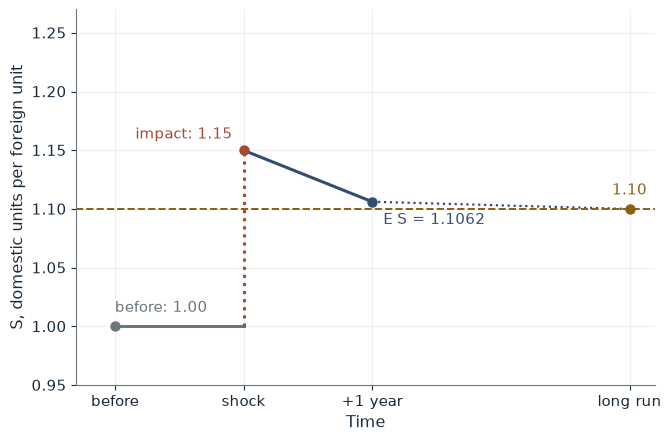

Expected S next year         1.1062
Expected change from impact  -3.81%
Overshoot beyond 1.10        5 points

Worked steps:
  1. 1 + i = 1.01, 1 + i* = 1.05
  2. E S = 1.15 x 1.01 / 1.05 = 1.1062
  3. Expected change = 1.1062 / 1.15 - 1 = 1.01 / 1.05 - 1 = -3.81%
  4. Overshoot = (1.15 - 1.10) x 100 = 5 points

E S = 1.15 x 1.01 / 1.05 = 1.1062, so the expected move is 1.1062 / 1.15 - 1 = 1.01 / 1.05 - 1 = -3.81%, an expected appreciation of 3.81 percent. The impact rate 1.15 lies 5 points beyond the long-run 1.10: the rate overshoots.


In [2]:
show(overshoot_picture(s_t=1.15, i=0.01))

Change one input, `i`, and hold the others at the book's values:

In [3]:
sweep(overshoot_picture, 'i', [0.01, 0.03, 0.05], {'s_t': 1.15}, ['Expected S next year', 'Expected change from impact'])

i | Expected S next year | Expected change from impact
0.01 | 1.1062 | -3.81%
0.03 | 1.1281 | -1.90%
0.05 | 1.1500 | 0.00%


The currency is expected to appreciate 3.81 percent from 1.15, which offsets the 4-point interest gap. The impact rate overshoots the long-run 1.10 by 5 points.

## 2. Covered interest parity: locking in the forward rate

Spot is 1.20 dollars per euro, the dollar rate 5 percent and the euro rate 2 percent.

$$F=1.20\left(\frac{1.05}{1.02}\right)\approx1.2353$$

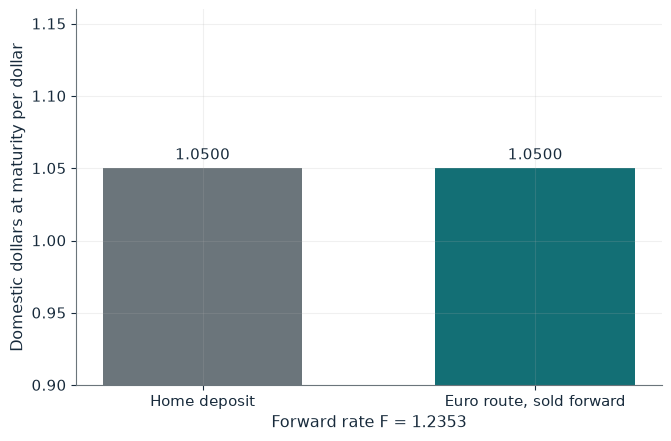

Parity forward rate        1.2353
Home payoff                1.0500
Euro route payoff          1.0500
Covered profit per dollar  0.0000
Trade                      none

Worked steps:
  1. F parity = 1.20 x 1.05 / 1.02 = 1.2353
  2. 1 / 1.20 = 0.8333 euros, x 1.02 = 0.8500
  3. Euro route = 0.8500 x 1.2353 = 1.0500
  4. Profit = 1.0500 - 1.0500 = 0.0000

Parity F = 1.20 x 1.05 / 1.02 = 1.2353. One dollar buys 1 / 1.20 = 0.8333 euros, which grow to 0.8333 x 1.02 = 0.8500, worth 0.8500 x 1.2353 = 1.0500 dollars against 1.0500 at home. The two routes pay the same, so there is no covered arbitrage.


In [4]:
show(parity_picture(fq='parity', i_d=0.05))

Change one input, `fq`, and hold the others at the book's values:

In [5]:
sweep(parity_picture, 'fq', ['1.20', 'parity', '1.26'], {'i_d': 0.05}, ['Euro route payoff', 'Covered profit per dollar', 'Trade'])

fq | Euro route payoff | Covered profit per dollar | Trade
1.20 | 1.0200 | -0.0300 | borrow euros, invest at home
parity | 1.0500 | 0.0000 | none
1.26 | 1.0710 | 0.0210 | borrow dollars, invest in euros


At parity both routes pay 1.05. At a quoted 1.26 the euro route pays 0.85 x 1.26 = 1.071, a covered profit of 0.021 per borrowed dollar before costs.

## 3. Balassa-Samuelson: productive traders, pricier services

$P_T=1$, services productivity $A_N=10$ and equal shares. Traded productivity rises from 20 to 30.

$$P_0=1^{0.5}2^{0.5}=\sqrt{2}\approx1.414, \qquad P_1=1^{0.5}3^{0.5}=\sqrt{3}\approx1.732$$

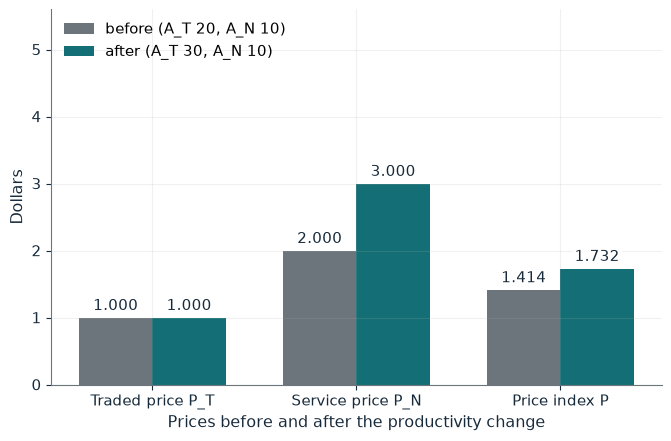

Wage                       30
Service price P_N          3.000
Price index                1.732
Index change               +22.5%
Real exchange rate change  -18.4%

Worked steps:
  1. w = 1 x 30 = 30
  2. P_N = 30 / 10 = 3.000
  3. P = 1^0.5 x 3.000^0.5 = 1.732
  4. Index change = 1.73205 / 1.41421 - 1 = +22.5%
  5. q change = 1.41421 / 1.73205 - 1 = -18.4%

w = 1 x 30 = 30, so P_N = 30 / 10 = 3.000 and P = sqrt(1 x 3.000) = 1.732, against sqrt(2) = 1.414 before. The index changes 1.73205 / 1.41421 - 1 = +22.5%, and with E and P* fixed the real exchange rate changes 1.41421 / 1.73205 - 1 = -18.4% (real appreciation). The traded price stays at 1.


In [6]:
show(balassa_picture(a_t=30, a_n=10))

Change one input, `a_t`, and hold the others at the book's values:

In [7]:
sweep(balassa_picture, 'a_t', [20, 25, 30, 40], {'a_n': 10}, ['Service price P_N', 'Price index', 'Real exchange rate change'])

a_t | Service price P_N | Price index | Real exchange rate change
20 | 2.000 | 1.414 | 0.0%
25 | 2.500 | 1.581 | -10.6%
30 | 3.000 | 1.732 | -18.4%
40 | 4.000 | 2.000 | -29.3%


The wage follows traded productivity to 30, services rise to 3 and the index rises 22.5 percent: a real appreciation of 18.4 percent with the traded price unchanged.

## 4. J-curve: worse before better

100 exports and 100 imports at 10; the import price rises to 12 after a 20 percent depreciation.

$$TB_1=100(10)-100(12)=-200, \qquad TB_4=1{,}375-840=535$$

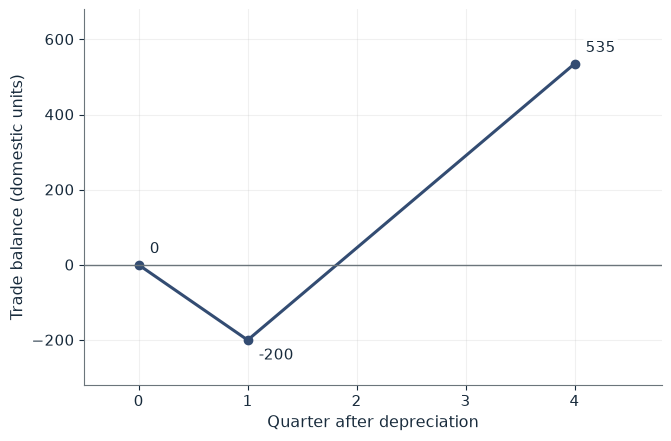

TB quarter 0  0
TB quarter 1  -200
TB quarter 4  535
Shape         a J: worse first, then above the start

Worked steps:
  1. TB0 = 100 x 10 - 100 x 10 = 0
  2. TB1 = 1,000 - 100 x 12 = -200
  3. Exports in quarter 4 = 125 x 11 = 1,375
  4. Imports in quarter 4 = 70 x 12 = 840
  5. TB4 = 1,375 - 840 = 535

TB0 = 100 x 10 - 100 x 10 = 0. Quarter 1: TB1 = 100 x 10 - 100 x 12 = 1,000 - 1,200 = -200. Quarter 4: TB4 = 125 x 11 - 70 x 12 = 1,375 - 840 = 535. The path is a J: worse first, then above the start.


In [8]:
show(jcurve_picture(resp='strong', pm=12))

Change one input, `resp`, and hold the others at the book's values:

In [9]:
sweep(jcurve_picture, 'resp', ['strong', 'weak', 'none'], {'pm': 12}, ['TB quarter 1', 'TB quarter 4'])

resp | TB quarter 1 | TB quarter 4
strong | -200 | 535
weak | -200 | 20
none | -200 | -100


The balance first falls to -200 because prices move before volumes. With the strong response it ends at 535; the weak response leaves only 20, and with no response it stays negative.

## Your numbers

Replace the inputs below with your own and run the cell. Every function above accepts any value in the range its section describes.

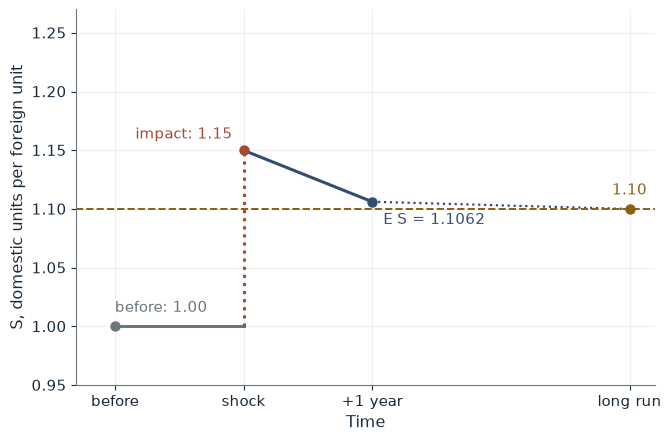

Expected S next year         1.1062
Expected change from impact  -3.81%
Overshoot beyond 1.10        5 points

Worked steps:
  1. 1 + i = 1.01, 1 + i* = 1.05
  2. E S = 1.15 x 1.01 / 1.05 = 1.1062
  3. Expected change = 1.1062 / 1.15 - 1 = 1.01 / 1.05 - 1 = -3.81%
  4. Overshoot = (1.15 - 1.10) x 100 = 5 points

E S = 1.15 x 1.01 / 1.05 = 1.1062, so the expected move is 1.1062 / 1.15 - 1 = 1.01 / 1.05 - 1 = -3.81%, an expected appreciation of 3.81 percent. The impact rate 1.15 lies 5 points beyond the long-run 1.10: the rate overshoots.


In [10]:
show(overshoot_picture(s_t=1.15, i=0.01))

## Practice

**1.** If i = 3 percent with an impact rate of 1.15, what is the expected rate next year?

<details><summary>Answer</summary>

1.15 x 1.03 / 1.05 = 1.1281.

</details>

**2.** At spot 1.20, rates 5 and 2 percent and a forward of 1.26, what is the covered profit per borrowed dollar?

<details><summary>Answer</summary>

(1 / 1.20) x 1.02 x 1.26 = 1.071, minus 1.05 = 0.021.

</details>

**3.** With the weak response (100 exports at 11, 90 imports at 12), what is the quarter-4 balance?

<details><summary>Answer</summary>

100 x 11 - 90 x 12 = 1,100 - 1,080 = 20.

</details>